## Celll 1 - Data Sources part A

---

- 建立花蓮市道路網路（使用 OpenStreetMap 與 osmnx）
- 將路網投影至 EPSG:3826 以進行精確空間分析
- 根據道路長度與速限資料計算基礎行車時間（travel_time）
- 若缺少速限資訊，使用預設速度 40 km/h 補足
- 建立可用於後續降雨影響與可達性分析的基礎交通網路模型

In [2]:
import os
import osmnx as ox

place_name = "Hualien City, Taiwan"
graphml_path = "hualien_drive.graphml"

if os.path.exists(graphml_path):
    print("Loading existing graph...")
    G = ox.load_graphml(graphml_path)
    G = ox.project_graph(G, to_crs="EPSG:3826")
else:
    print("Fetching road network from OSM...")
    G = ox.graph_from_place(place_name, network_type="drive")
    G = ox.project_graph(G, to_crs="EPSG:3826")

# === 計算 travel_time（不論是否重新下載）===
DEFAULT_SPEED_KMH = 40

for u, v, data in G.edges(data=True):
    length = data.get("length", 0)
    maxspeed = data.get("maxspeed", None)
    speed = DEFAULT_SPEED_KMH

    if maxspeed is not None:
        try:
            if isinstance(maxspeed, list):
                maxspeed = maxspeed[0]
            raw = str(maxspeed).strip()
            is_mph = "mph" in raw.lower()
            speed = float(raw.lower().replace("mph", "").strip())
            if is_mph:
                speed *= 1.60934
        except (ValueError, TypeError):
            speed = DEFAULT_SPEED_KMH

    data["speed_kph"] = speed
    data["travel_time"] = length / (speed / 3.6)

ox.save_graphml(G, graphml_path)
print("Graph saved with travel_time.")

# 驗證
edges = ox.graph_to_gdfs(G, nodes=False)
print(f"總邊數: {len(edges)}")
print(edges[["length", "speed_kph", "travel_time"]].describe())


Loading existing graph...
Graph saved with travel_time.
總邊數: 4577
            length    speed_kph  travel_time
count  4577.000000  4577.000000  4577.000000
mean    107.540771    40.091763     9.652156
std     111.071616     0.998410     9.943206
min       3.041973    30.000000     0.273778
25%      53.523218    40.000000     4.801485
50%      80.849663    40.000000     7.255130
75%     123.660086    40.000000    11.117983
max    1701.617720    50.000000   153.145595


## Celll 2 - Data Sources part B & C
---
* 載入環境變數（CRS、目標縣市）以統一分析設定
* 讀取地形風險資料（terrain_risk_audit.json）
* 讀取避難收容所資料（shelter_marked.csv）
* 讀取行政區邊界圖層（TOWN_MOI shapefile）
* 檢查資料欄位結構，確保後續欄位對齊與資料整合
* 建立後續空間分析（避難所、地形、行政區）的基礎資料集

### Captain's Log — Shelter and Terrain Integration
- In this step, shelter locations are converted into a GeoDataFrame using longitude and latitude.
Then, terrain risk data is spatially joined to each shelter to identify environmental risk exposure.





In [3]:
import pandas as pd
import numpy as np
import geopandas as gpd
from dotenv import load_dotenv
import rasterio

load_dotenv()

CRS = os.getenv("PROJECT_CRS")
TARGET_COUNTY = os.getenv("TARGET_COUNTY")
print(CRS)
print(TARGET_COUNTY)

# 讀取模擬資料
terrain_df = pd.read_json("../Data/terrain_risk_audit.json")
shelter_df = pd.read_csv("../Data/shelter_marked.csv")
boundary_df = gpd.read_file("../Data/TOWN_MOI_1140318/TOWN_MOI_1140318.shp")


print(shelter_df.columns)
print(terrain_df.columns)

3826
花蓮縣
Index(['序號', '縣市及鄉鎮市區', '村里', '避難收容處所地址', '經度', '緯度', '避難收容處所名稱', '預計收容村里',
       '預計收容人數', '適用災害類別', '管理人姓名', '管理人電話', '室內', '室外', '適合避難弱者安置', 'TOWNID',
       'TOWNCODE', 'COUNTYNAME', 'TOWNNAME', 'TOWNENG', 'COUNTYID',
       'COUNTYCODE', 'risk_level'],
      dtype='str')
Index(['shelter_id', 'name', 'risk_level', 'mean_elevation', 'max_slope'], dtype='str')


## Cell 3 - Shelter Data Integration

---
* 統一 shelter 與 terrain 資料的主鍵（shelter_id）並轉為整數型態
* 將避難所資料轉為 GeoDataFrame（由經緯度建立點位）
* 將座標系統由 EPSG:4326 投影至分析用 CRS
* 合併地形風險資料（terrain_df）至避難所資料
* 移除不必要欄位，保留分析所需資訊
* 將風險欄位重新命名為 `terrain_risk`
* 輸出花蓮避難所 GeoJSON 作為後續分析基礎資料

---
### Captain’s Log — Filtering Hualien Shelters

* 成功整合避難所與地形風險資料
* 清理冗餘欄位，確保資料結構簡潔
* 確認每筆避難所具備空間座標與風險資訊
* 建立乾淨且可分析的花蓮避難所資料集
* 為後續可達性與風險分析奠定基礎


In [4]:
import pandas as pd
import geopandas as gpd

# === 1. 欄位對齊 ===
shelter_df = shelter_df.rename(columns={"序號": "shelter_id"})
shelter_df["shelter_id"] = shelter_df["shelter_id"].astype(int)
terrain_df["shelter_id"] = terrain_df["shelter_id"].astype(int)

# === 2. 建立 GeoDataFrame ===
shelter_gdf = gpd.GeoDataFrame(
    shelter_df,
    geometry=gpd.points_from_xy(shelter_df["經度"], shelter_df["緯度"]),
    crs="EPSG:4326"
).to_crs(epsg=CRS)  # 投影到台灣常用座標系統

# === 3. merge terrain ===
shelter_hualien = shelter_gdf.merge(
    terrain_df,
    on="shelter_id",
    how="inner"
)
shelter_hualien_df =shelter_hualien.copy()
shelter_hualien_df = shelter_hualien_df.drop(columns=["risk_level_x", "預計收容村里", "預計收容人數", "適用災害類別", "管理人姓名", "管理人電話", "室內", "室外", "適合避難弱者安置",
                                                      "TOWNNAME", "TOWNENG", "TOWNID", "TOWNCODE", "COUNTYID", "COUNTYCODE", "name"])
shelter_hualien_df = shelter_hualien_df.rename(columns={"risk_level_y": "terrain_risk"})
print("剩下筆數:", len(shelter_hualien_df))
print(shelter_hualien_df.columns)
shelter_hualien_df.to_file("shelter_hualien_df.geojson", driver="GeoJSON")



剩下筆數: 198
Index(['shelter_id', '縣市及鄉鎮市區', '村里', '避難收容處所地址', '經度', '緯度', '避難收容處所名稱',
       'COUNTYNAME', 'geometry', 'terrain_risk', 'mean_elevation',
       'max_slope'],
      dtype='str')


## Cell 4 - Network Simplification & Bottleneck Detection

---

* 將 MultiDiGraph 轉換為 DiGraph，保留每對節點間 travel_time 最短的邊
* 簡化路網結構，避免多重邊影響最短路徑計算
* 使用 Betweenness Centrality 評估節點在整體路網中的重要性
* 以 travel_time 作為權重，反映實際通行成本
* 將 centrality 正規化（0–1），便於不同節點間比較
* 篩選 Top 5 高 centrality 節點作為潛在交通瓶頸

---

### Captain’s Log — Identifying Bottlenecks

* 成功將複雜路網簡化為可分析的單一導向圖
* 完成全網路節點中心性計算（計算成本較高）
* 辨識出交通流量關鍵節點（bottlenecks）
* 為後續災害情境下的路網脆弱性分析提供依據


In [5]:
import networkx as nx

# MultiDiGraph → DiGraph（保留最短 travel_time 的邊）
G_di = nx.DiGraph()
for u, v, data in G.edges(data=True):
    if G_di.has_edge(u, v):
        if data.get("travel_time", float("inf")) < G_di[u][v].get("travel_time", float("inf")):
            G_di[u][v].update(data)
    else:
        G_di.add_edge(u, v, **data)

print(f"節點數: {G_di.number_of_nodes()}, 邊數: {G_di.number_of_edges()}")

print("⏳ Calculating Betweenness Centrality (this may take a while)...")
centrality = nx.betweenness_centrality(
    G_di,
    weight="travel_time",  # 以行駛時間為成本
    normalized=True,       # 結果介於 0~1，利於比較
    seed=42
)
print("✅ Done")

# Top 5 瓶頸節點
top_5_nodes = sorted(centrality.items(), key=lambda x: x[1], reverse=True)[:5]

print("\nTop 5 Bottleneck Nodes:")
for rank, (node_id, cent_val) in enumerate(top_5_nodes, 1):
    node_data = G_di.nodes[node_id]
    print(f"  {rank}. Node {node_id}  Centrality = {cent_val:.6f}")


節點數: 1573, 邊數: 4559
⏳ Calculating Betweenness Centrality (this may take a while)...
✅ Done

Top 5 Bottleneck Nodes:
  1. Node 1119847832  Centrality = 0.231161
  2. Node 601584086  Centrality = 0.215646
  3. Node 906775386  Centrality = 0.211292
  4. Node 906775240  Centrality = 0.196643
  5. Node 883096197  Centrality = 0.193985


## Cell 5 - Bottleneck Visualization & Risk Mapping

---
* 將 Top 5 瓶頸節點轉為 GeoDataFrame（含座標與 centrality）
* 透過 `sjoin_nearest` 將每個節點對應最近避難所之地形風險（terrain_risk）
* 計算節點與避難所的距離（dist_to_shelter）
* 將風險等級轉換為數值（low → extremely_high）以利視覺化
* 以道路網路為底圖，疊加瓶頸節點位置
* 使用顏色表示地形風險（綠 → 紅），大小表示 centrality 強度
* 加入 colorbar 提供風險等級對照

---
### Captain’s Log — Mapping Critical Nodes

* 成功將關鍵節點與空間風險資訊整合
* 瓶頸節點不僅反映交通重要性，也結合地形脆弱性
* 視覺化結果可快速辨識高風險且高影響力區域
* 為後續防災決策（如道路優先清理）提供空間依據


 rank    node_id  centrality terrain_risk  dist_to_shelter
    1 1119847832    0.231161         high       223.871069
    2  601584086    0.215646       medium       341.372623
    3  906775386    0.211292          low       444.171091
    4  906775240    0.196643       medium       130.496198
    5  883096197    0.193985       medium        85.900485


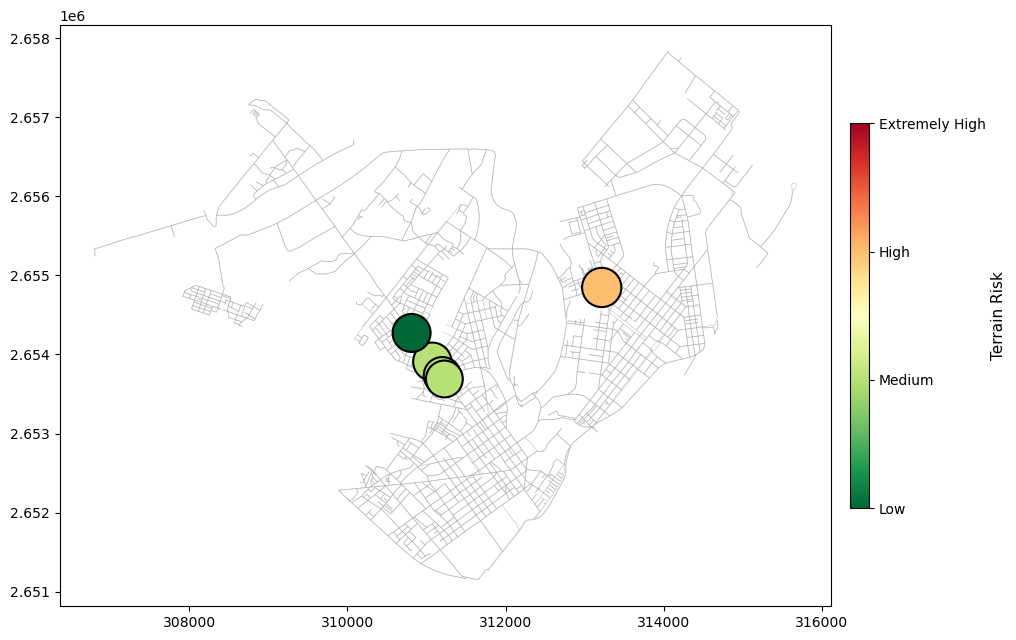

In [6]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
from shapely.geometry import Point

# ================================================================
# 1. 把 Top 5 節點轉成 GeoDataFrame
# ================================================================
top5_records = []
for rank, (node_id, cent_val) in enumerate(top_5_nodes, 1):
    node_data = G.nodes[node_id]
    top5_records.append({
        "rank":        rank,
        "node_id":     node_id,
        "centrality":  cent_val,
        "geometry":    Point(node_data["x"], node_data["y"])  # EPSG:3826
    })

top5_gdf = gpd.GeoDataFrame(top5_records, crs=f"EPSG:{CRS}")

# ================================================================
# 2. sjoin_nearest → 從 shelter_hualien_df 取 terrain_risk
# ================================================================
# shelter_hualien_df 已經是 EPSG:3826，直接 join
top5_gdf = gpd.sjoin_nearest(
    top5_gdf,
    shelter_hualien_df[["shelter_id", "terrain_risk", "geometry"]],
    how="left",
    distance_col="dist_to_shelter"
)

print(top5_gdf[["rank", "node_id", "centrality", "terrain_risk", "dist_to_shelter"]].to_string(index=False))

# ================================================================
# 3. visualize
# ================================================================

fig, ax = plt.subplots(figsize=(12, 10))

# --- 底圖：道路網路 ---
edges_gdf = ox.graph_to_gdfs(G, nodes=False)
edges_gdf.plot(ax=ax, linewidth=0.5, color="#AAAAAA", alpha=0.6, zorder=1)

# --- terrain_risk 文字 → 數值 ---
risk_map = {
    "low":           1,
    "medium":        2,
    "high":          3,
    "extremely_high": 4
}
top5_gdf["risk_num"] = top5_gdf["terrain_risk"].map(risk_map)

# --- 色彩設定 ---
norm = mcolors.Normalize(vmin=1, vmax=4)
cmap = cm.RdYlGn_r

sc = ax.scatter(
    top5_gdf.geometry.x,
    top5_gdf.geometry.y,
    c=top5_gdf["risk_num"],
    cmap=cmap,
    norm=norm,
    s=top5_gdf["centrality"] / top5_gdf["centrality"].max() * 600 + 200,
    edgecolors="black",
    linewidths=1.5,
    zorder=3
)

# --- Colorbar 顯示文字標籤 ---
cbar = plt.colorbar(sc, ax=ax, shrink=0.5, pad=0.02)
cbar.set_label("Terrain Risk", fontsize=11)
cbar.set_ticks([1, 2, 3, 4])
cbar.set_ticklabels(["Low", "Medium", "High", "Extremely High"])


## Cell 6 - Rainfall to Congestion Modeling

---
* 建立函數將降雨量轉換為壅塞係數（congestion factor, cf）
* 提供三種方法：

  * **Threshold**：分段設定（主要分析方法）
  * **Linear**：線性增加（平滑變化）
  * **Exponential**：指數成長（模擬極端情境）
* Threshold 方法將降雨分為四個等級（無影響 → 嚴重壅塞）
* 限制 cf 上限（約 0.9–0.95）避免速度趨近於 0
* 提供彈性方法選擇以支援敏感度分析（sensitivity analysis）
* 透過測試數據驗證不同降雨強度對應的壅塞程度

---
### Captain’s Log — Modeling Rain Impact

* 成功將氣象資料轉換為交通影響指標（cf）
* 建立可切換的多種模型，提高分析彈性
* Threshold 方法作為主要情境模擬依據
* 為後續 travel_time 調整與路網分析提供核心機制


In [24]:
def rain_to_congestion(rainfall_mm, method='threshold'):
    """
    Convert rainfall intensity to congestion factor (cf)
    """
    
    # --- Threshold 方法（最重要）---
    if method == 'threshold':
        if rainfall_mm < 10:
            cf = 0.0
        elif rainfall_mm < 40:
            cf = 0.3
        elif rainfall_mm < 80:
            cf = 0.6
        else:
            cf = 0.9

    # --- Linear 方法（加分用）---
    elif method == 'linear':
        cf = min(rainfall_mm / 100 * 0.9, 0.95)

    # --- Exponential 方法（進階）---
    elif method == 'exponential':
        import numpy as np
        cf = 0.95 * (1 - np.exp(-rainfall_mm / 50))

    # --- 預設 fallback ---
    else:
        raise ValueError("method must be 'threshold', 'linear', or 'exponential'")
    
    return cf

# Testing
rain_test = [0, 10, 40, 80, 100, 130.5]
for rain in rain_test:
    cf = rain_to_congestion(rain, method='threshold')
    print(f"Rainfall {rain:.1f} mm/hr → Congestion Factor {cf}")

Rainfall 0.0 mm/hr → Congestion Factor 0.0
Rainfall 10.0 mm/hr → Congestion Factor 0.3
Rainfall 40.0 mm/hr → Congestion Factor 0.6
Rainfall 80.0 mm/hr → Congestion Factor 0.9
Rainfall 100.0 mm/hr → Congestion Factor 0.9
Rainfall 130.5 mm/hr → Congestion Factor 0.9


## Cell 7 - Rainfall Data Processing & Geospatial Integration

---
* 讀取參考測站資料（含經緯度）建立座標對照表
* 讀取目標日期降雨資料（rain_20230904）
* 將雨量欄位（HOUR_6）轉為數值並清理無效值（-998、NaN）
* 合併測站座標與降雨資料（依 station_id）
* 檢查有效測站數與雨量範圍（確認資料品質）
* 將測站資料轉為 GeoDataFrame（由經緯度建立點位）
* 投影至分析用 CRS（EPSG:3826）以利後續空間分析

---
### Captain’s Log — Tracking the Storm

* 成功整合降雨資料與測站空間位置
* 清理異常值，確保雨量數據可靠
* 確認降雨範圍具備分析價值（非全為低雨量）
* 建立可用於空間插值與路網影響分析的測站資料集


In [25]:
import pandas as pd
import geopandas as gpd

# ================================================================
# 1. 讀取有座標的參考檔，建立測站座標對照表
# ================================================================
ref_df = pd.read_csv("../Data/rain_20240725.csv")
ref_df = ref_df.rename(columns={"StationId": "station_id"})
station_coords = ref_df[["station_id", "StationLatitude", "StationLongitude"]].drop_duplicates()

# ================================================================
# 2. 讀取 rain_20230904.csv，過濾無效值
# ================================================================
rain_df = pd.read_csv("../Data/rain_20230904.csv")
rain_df = rain_df.rename(columns={"station_id": "station_id"})
rain_df["HOUR_6"] = pd.to_numeric(rain_df["HOUR_6"], errors="coerce")
rain_df = rain_df.replace(-998, pd.NA).dropna(subset=["HOUR_6"])
print(f"有效測站數: {len(rain_df)}")

# ================================================================
# 3. Merge 座標
# ================================================================
rain_with_coords = rain_df.merge(station_coords, on="station_id", how="inner")
print(f"成功對應座標的測站數: {len(rain_with_coords)}")
print(f"HOUR_6 範圍: {rain_with_coords['HOUR_6'].min():.1f} ~ {rain_with_coords['HOUR_6'].max():.1f} mm")

# ================================================================
# 4. 建立 GeoDataFrame
# ================================================================
station_gdf = gpd.GeoDataFrame(
    rain_with_coords,
    geometry=gpd.points_from_xy(
        rain_with_coords["StationLongitude"],
        rain_with_coords["StationLatitude"]
    ),
    crs="EPSG:4326"
).to_crs(epsg=int(CRS))

print(f"\n✅ station_gdf 建立完成，CRS: {station_gdf.crs}")
print(station_gdf[["station_id", "HOUR_6", "geometry"]].head())


有效測站數: 126442
成功對應座標的測站數: 114498
HOUR_6 範圍: 0.2 ~ 374.5 mm

✅ station_gdf 建立完成，CRS: EPSG:3826
  station_id HOUR_6                        geometry
0     C1S870   24.0    POINT (289150.21 2560972.26)
1     C0G770    3.0  POINT (192805.296 2659710.011)
2     O1H540    4.0  POINT (236923.429 2630662.348)
3     81U900   10.5  POINT (339577.692 2758931.987)
4     81E870    0.5  POINT (240448.305 2688054.785)


## Cell 8 - Rainfall Assignment & Travel Time Adjustment

---
* 建立測站影響範圍（5 km buffer）以模擬降雨空間影響
* 取得道路節點 GeoDataFrame 作為雨量分配對象
* 使用 `sjoin_nearest` 將每個節點對應最近測站雨量（HOUR_6）
* 若節點未被覆蓋，雨量設為 0（確保完整性）
* 將節點雨量轉換為 dictionary，便於快速查詢
* 以邊兩端節點平均雨量估計該路段降雨強度
* 使用 `rain_to_congestion()` 將雨量轉為壅塞係數（cf）
* 根據 cf 調整 travel_time，建立 `travel_time_adj`
* 將 rainfall、cf、travel_time_adj 寫回 Graph

---
### Captain’s Log — Storm Hits the Network

* 成功將降雨影響從測站擴展至整體路網
* 路段速度依降雨強度動態調整，反映真實交通情境
* cf 分布顯示降雨對不同區域影響程度不一
* 建立災後路網模型，為可達性與避難分析提供基礎


In [26]:
# ================================================================
# 1. 建立測站 Buffer（5km）
# ================================================================
BUFFER_RADIUS = 5000

rain_buffer = station_gdf.copy()
rain_buffer["geometry"] = rain_buffer.buffer(BUFFER_RADIUS)

# ================================================================
# 2. 取得道路節點 GeoDataFrame
# ================================================================
nodes_gdf = ox.graph_to_gdfs(G, edges=False).reset_index()

# ================================================================
# 3. sjoin_nearest：道路節點 × 測站 Buffer
# ================================================================
joined = gpd.sjoin_nearest(
    nodes_gdf[["osmid", "geometry"]],
    rain_buffer[["geometry", "HOUR_6"]],
    how="left",
    distance_col="dist_to_station"
)

# 同一節點對應多筆時取最近的
joined = (
    joined.sort_values("dist_to_station")
    .groupby("osmid", as_index=False)
    .first()
)
joined["HOUR_6"] = joined["HOUR_6"].fillna(0)

print(f"節點雨量範圍: {joined['HOUR_6'].min():.1f} ~ {joined['HOUR_6'].max():.1f} mm")
print(f"雨量 > 0 的節點數: {(joined['HOUR_6'] > 0).sum()}")

# ================================================================
# 4. 計算 cf，寫回 Graph（兩端節點平均雨量）
# ================================================================
node_rain = joined.set_index("osmid")["HOUR_6"].to_dict()

for u, v, k, data in G.edges(keys=True, data=True):
    rain_mm = (node_rain.get(u, 0) + node_rain.get(v, 0)) / 2
    cf = rain_to_congestion(rain_mm)
    data["rainfall_mm"]      = rain_mm
    data["cf"]               = cf
    data["travel_time_adj"]  = data["length"] / (
        (data.get("speed_kph", 40) / 3.6) * (1 - cf)
    )

# ================================================================
# 5. 確認結果
# ================================================================
cf_counts = {}
for u, v, k, data in G.edges(keys=True, data=True):
    cf = data.get("cf", 0)
    cf_counts[cf] = cf_counts.get(cf, 0) + 1

print("\n✅ travel_time_adj 寫回 Graph 完成")
print("cf 分佈:")
for cf_val, count in sorted(cf_counts.items()):
    print(f"  cf={cf_val:.2f}  {count} 條路段")


節點雨量範圍: 0.5 ~ 122.5 mm
雨量 > 0 的節點數: 1573

✅ travel_time_adj 寫回 Graph 完成
cf 分佈:
  cf=0.00  529 條路段
  cf=0.30  1794 條路段
  cf=0.60  811 條路段
  cf=0.90  1443 條路段


## Cell 9 - Isochrone Analysis & Accessibility Impact

---
* 隨機選取 5 個避難設施作為分析起點
* 使用 Dijkstra 演算法計算指定時間內可達節點（isochrone）
* 以 alphashape 將可達節點轉換為空間範圍（polygon）
* 設定 5 分鐘與 10 分鐘兩種可達時間門檻
* 分別計算災前（travel_time）與災後（travel_time_adj）可達範圍
* 計算可達面積（km²）並比較變化
* 定義 shrinkage 指標衡量可達性縮減比例
* 儲存等時圈多邊形以利後續地圖視覺化

---
### Captain’s Log — Accessibility Under Pressure

* 成功模擬降雨對避難可達性的影響
* 可達範圍在災後明顯縮小，顯示交通系統受阻
* 不同設施受影響程度不一，呈現空間差異性
* 建立量化指標（shrinkage）評估避難服務能力變化
* 為防災規劃與資源配置提供關鍵依據


In [ ]:
import networkx as nx
from shapely.geometry import MultiPoint
from shapely.ops import unary_union
import alphashape

# ================================================================
# 1. 選 5 個關鍵設施（從 shelter_hualien_df 取）
# ================================================================
key_facilities = shelter_hualien_df.sample(5, random_state=42).reset_index(drop=True)
print("選定設施：")
print(key_facilities[["shelter_id", "避難收容處所名稱", "terrain_risk"]])

# ================================================================
# 2. 等時圈計算函式
# ================================================================
def get_isochrone(G, origin_node, weight, cutoff_sec, alpha=0.01):
    """
    從 origin_node 出發，計算 cutoff_sec 秒內可到達節點，回傳多邊形
    """
    lengths = nx.single_source_dijkstra_path_length(
        G, origin_node, cutoff=cutoff_sec, weight=weight
    )
    reachable_nodes = list(lengths.keys())

    if len(reachable_nodes) < 3:
        return None

    points = [
        (G.nodes[n]["x"], G.nodes[n]["y"]) for n in reachable_nodes
    ]
    try:
        poly = alphashape.alphashape(points, alpha)
    except Exception:
        poly = MultiPoint(points).convex_hull

    return poly

# ================================================================
# 3. 對每個設施計算等時圈與縮減比
# ================================================================
CUTOFFS = [5 * 60, 10 * 60]  # 5分鐘、10分鐘（秒）
ALPHA = 0.005

results = []

for _, facility in key_facilities.iterrows():
    # 找最近節點
    origin_node = ox.distance.nearest_nodes(
        G, facility.geometry.x, facility.geometry.y
    )

    row = {
        "shelter_id": facility["shelter_id"],
        "名稱": facility["避難收容處所名稱"],
        "terrain_risk": facility["terrain_risk"],
    }

    for cutoff in CUTOFFS:
        label = f"{cutoff // 60}min"

        # 災前
        poly_before = get_isochrone(G, origin_node, "travel_time", cutoff, ALPHA)
        area_before = poly_before.area / 1e6 if poly_before else 0  # km²

        # 災後
        poly_after = get_isochrone(G, origin_node, "travel_time_adj", cutoff, ALPHA)
        area_after = poly_after.area / 1e6 if poly_after else 0

        shrinkage = 1 - (area_after / area_before) if area_before > 0 else None

        row[f"before_{label}_km2"] = round(area_before, 4)
        row[f"after_{label}_km2"]  = round(area_after, 4)
        row[f"shrinkage_{label}"]  = f"{shrinkage * 100:.1f}%" if shrinkage is not None else "N/A"

        # 儲存多邊形供後續畫圖
        row[f"poly_before_{label}"] = poly_before
        row[f"poly_after_{label}"]  = poly_after

    results.append(row)
    print(f"✅ {facility['避難收容處所名稱']} 完成")

# ================================================================
# 4. 輸出 Accessibility Impact Table
# ================================================================
impact_df = pd.DataFrame(results)[[
    "名稱", "terrain_risk",
    "before_5min_km2", "after_5min_km2", "shrinkage_5min",
    "before_10min_km2", "after_10min_km2", "shrinkage_10min"
]]

impact_df.columns = [
    "Facility", "Terrain Risk",
    "Pre-Disaster 5min (km²)", "Post-Disaster 5min (km²)", "Shrinkage 5min",
    "Pre-Disaster 10min (km²)", "Post-Disaster 10min (km²)", "Shrinkage 10min"
]

impact_df

選定設施：
   shelter_id  避難收容處所名稱    terrain_risk
0        2180    大興活動中心  extremely_high
1        2701    鹽寮活動中心            high
2        1500  清水社區活動中心  extremely_high
3        2990    宜昌活動中心            high
4        3055      中華國小  extremely_high
✅ 大興活動中心 完成
✅ 鹽寮活動中心 完成
✅ 清水社區活動中心 完成
✅ 宜昌活動中心 完成
✅ 中華國小 完成


,Facility,Terrain Risk,Pre-Disaster 5min (km²),Post-Disaster 5min (km²),Shrinkage 5min,Pre-Disaster 10min (km²),Post-Disaster 10min (km²),Shrinkage 10min
0,大興活動中心,extremely_high,4.3314,0.9213,78.7%,12.4007,4.2228,65.9%
1,鹽寮活動中心,high,4.2812,0.5063,88.2%,12.2880,4.0862,66.7%
2,清水社區活動中心,extremely_high,4.3314,0.9213,78.7%,12.4007,4.2228,65.9%
3,宜昌活動中心,high,4.5811,1.2356,73.0%,12.6775,6.0098,52.6%
4,中華國小,extremely_high,9.7656,4.8622,50.2%,14.0034,9.8410,29.7%


## Cell 10 - Isolated Shelter Detection

---
* 從路網中提取每條邊的壅塞係數（cf）
* 計算每條路段的中點作為空間代表位置
* 建立路段中點 GeoDataFrame 以利距離計算
* 對每個避難所搜尋最近的 N 條路段（預設 5 條）
* 計算這些路段的平均 cf 作為周邊交通狀況指標
* 設定門檻（avg_cf > 0.7）判定避難所是否「近似孤立」
* 篩選出高壅塞、可能難以進出的避難所
* 建立 isolated_gdf 與純表格 isolated_df 作為輸出結果

---
### Captain’s Log — Detecting Isolation

* 成功辨識受降雨影響嚴重的避難設施
* 高 cf 區域顯示道路通行能力顯著下降
* 部分避難所可能面臨交通中斷或救援困難
* 建立「孤立避難所」指標，強化風險辨識能力
* 為緊急應變與資源優先配置提供決策依據


In [48]:
# ================================================================
# 1. 取得所有邊的 cf 資料
# ================================================================
edges_gdf = ox.graph_to_gdfs(G, nodes=False).reset_index()
edges_gdf["cf"] = edges_gdf.apply(
    lambda row: G[row["u"]][row["v"]][row["key"]].get("cf", 0), axis=1
)
edges_gdf["midpoint"] = edges_gdf.geometry.interpolate(0.5, normalized=True)
edges_mid_gdf = gpd.GeoDataFrame(
    edges_gdf[["u", "v", "key", "cf"]],
    geometry=edges_gdf["midpoint"],
    crs=f"EPSG:{CRS}"
)

# ================================================================
# 2. 對每個避難所找最近的 N 條路段，計算平均 cf
# ================================================================
N_EDGES = 5  # 取最近 5 條路段

isolated_list = []

for _, shelter in shelter_hualien_df.iterrows():
    # 找最近 N 條路段中點
    distances = edges_mid_gdf.geometry.distance(shelter.geometry)
    nearest_edges = edges_mid_gdf.loc[distances.nsmallest(N_EDGES).index]
    avg_cf = nearest_edges["cf"].mean()

    if avg_cf > 0.7:
        isolated_list.append({
            "shelter_id": shelter["shelter_id"],
            "名稱": shelter["避難收容處所名稱"],
            "terrain_risk": shelter["terrain_risk"],
            "avg_cf": round(avg_cf, 3),
            "geometry": shelter.geometry
        })

isolated_gdf = gpd.GeoDataFrame(isolated_list, crs=f"EPSG:{CRS}")

print(f"孤立避難所數量: {len(isolated_gdf)}")

# 儲存至 output（不含 geometry 的純表格）
isolated_df = isolated_gdf[["shelter_id", "名稱", "terrain_risk", "avg_cf"]].copy()

# 顯示 DataFrame
isolated_df


孤立避難所數量: 16


,shelter_id,名稱,terrain_risk,avg_cf
0,2660,西林社區活動中心,high,0.9
1,2668,西林天主堂,high,0.9
2,2903,文蘭活動中心,extremely_high,0.9
3,2950,銅門收容所,extremely_high,0.9
4,2981,吉安國小,low,0.9
5,2984,吉安活動中心,low,0.9
6,3023,慶豐活動中心,high,0.9
7,3049,永安活動中心,medium,0.9
8,3061,鑄強國小,medium,0.9
9,3064,太昌活動中心,low,0.9


## Cell 11 - Isochrone Visualization (Pre vs Post Disaster)

---
* 設定中文字型（Microsoft JhengHei）以確保圖表正確顯示
* 建立輔助函式計算等時圈節點與轉換為多邊形範圍
* 將避難設施對應至最近路網節點作為分析起點
* 繪製每個設施在災前與災後的等時圈比較（左右對照）
* 使用 5 分鐘與 10 分鐘兩種時間門檻呈現可達範圍
* 以顏色區分不同時間尺度（紅=5分鐘，藍=10分鐘）
* 標示設施位置並顯示對應可達面積（km²）
* 疊加於道路網路底圖以呈現真實空間分布
* 輸出圖像（isochrone_comparison.png）供報告與展示使用

---
### Captain’s Log — Visualizing Accessibility Loss

* 成功將抽象的可達性變化轉為直觀地圖
* 災後等時圈明顯縮小，顯示交通效率下降
* 不同設施之間呈現顯著空間差異
* 視覺化結果強化研究說服力與溝通效果
* 提供決策者快速理解災害影響的工具


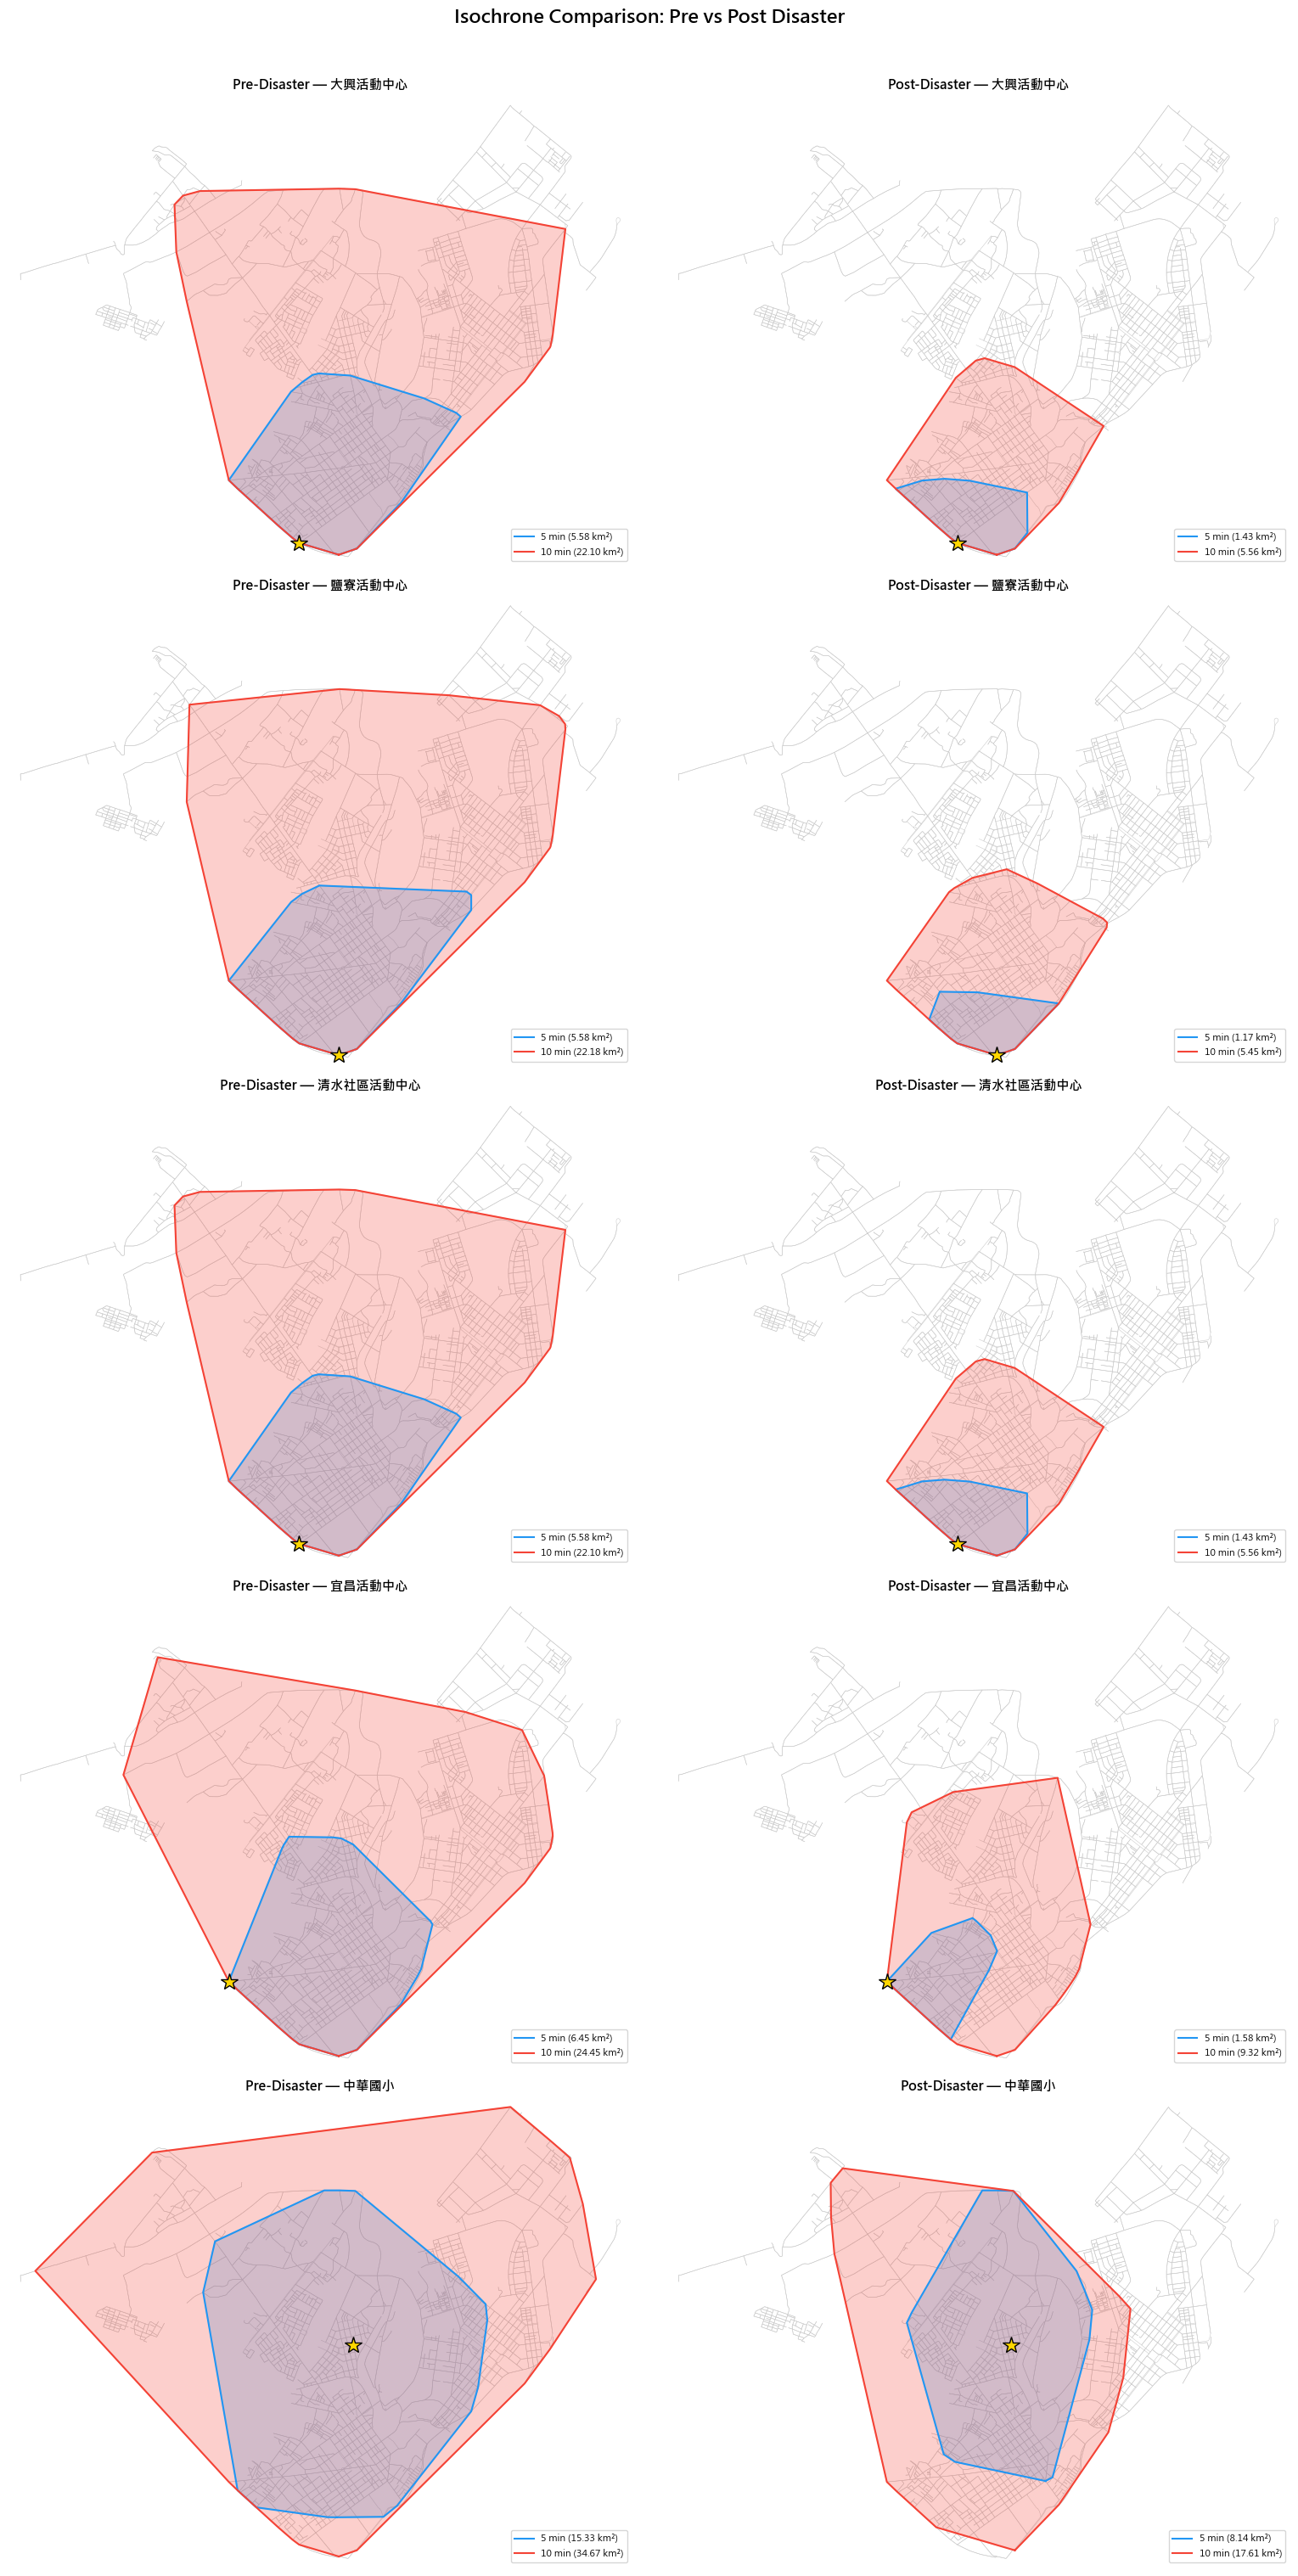

✅ Isochrone visualization complete


In [51]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from shapely.geometry import MultiPoint
import networkx as nx

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# Windows 微軟正黑體
plt.rcParams['font.family'] = 'Microsoft JhengHei'
plt.rcParams['axes.unicode_minus'] = False  # 負號正常顯示

# ================================================================
# 輔助函式
# ================================================================
def compute_isochrone(G, origin_node, weight, cutoff):
    lengths = nx.single_source_dijkstra_path_length(
        G, origin_node, cutoff=cutoff, weight=weight
    )
    return list(lengths.keys())

def nodes_to_polygon(G, node_list):
    if len(node_list) < 3:
        return None, 0
    points = [(G.nodes[n]['x'], G.nodes[n]['y']) for n in node_list]
    poly = MultiPoint(points).convex_hull
    return poly, poly.area

# ================================================================
# 選 5 個設施（從 key_facilities 取最近節點）
# ================================================================
facility_nodes = []
for _, row in key_facilities.iterrows():
    node = ox.distance.nearest_nodes(G, row.geometry.x, row.geometry.y)
    facility_nodes.append((node, row["避難收容處所名稱"]))

# ================================================================
# 畫圖：每個設施一列，左=災前，右=災後
# ================================================================
CUTOFFS = [5 * 60, 10 * 60]
COLORS  = ['#2196F3', '#F44336']  # 藍=10min, 紅=5min

fig, axes = plt.subplots(5, 2, figsize=(16, 30))

for i, (fnode, fname) in enumerate(facility_nodes):
    for j, (weight_attr, title_prefix) in enumerate([
        ('travel_time',     'Pre-Disaster'),
        ('travel_time_adj', 'Post-Disaster')
    ]):
        ax = axes[i][j]
        ox.plot_graph(G, ax=ax, node_size=0, edge_color='#CCCCCC',
                      edge_linewidth=0.4, show=False, bgcolor='white')

        for cutoff, color in zip(CUTOFFS, COLORS):
            reachable = compute_isochrone(G, fnode, weight_attr, cutoff)
            poly, area = nodes_to_polygon(G, reachable)
            if poly and poly.geom_type == 'Polygon':
                x, y = poly.exterior.xy
                ax.fill(x, y, alpha=0.25, color=color)
                ax.plot(x, y, color=color, linewidth=1.5,
                        label=f'{cutoff//60} min ({area/1e6:.2f} km²)')

        # 標記設施位置
        ax.plot(G.nodes[fnode]['x'], G.nodes[fnode]['y'],
                marker='*', markersize=15, color='gold',
                markeredgecolor='black', zorder=10)

        ax.set_title(f'{title_prefix} — {fname}', fontsize=11, fontweight='bold')
        ax.legend(loc='lower right', fontsize=8)

plt.suptitle('Isochrone Comparison: Pre vs Post Disaster', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('isochrone_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Isochrone visualization complete")


# AI Strategy Briefing
## Typhoon  (海葵颱風) — Hualien County Disaster Prevention Command Center
 
---
 
## Top 5 Bottleneck Nodes
 
| Rank | Node ID | Centrality | Terrain Risk | Dist to Shelter (m) |
|------|------------|------------|--------------|----------------------|
| 1 | 1119847832 | 0.2312 | High | 223.9 |
| 2 | 601584086 | 0.2156 | Medium | 341.4 |
| 3 | 906775386 | 0.2113 | Low | 444.2 |
| 4 | 906775240 | 0.1966 | Medium | 130.5 |
| 5 | 883096197 | 0.1940 | Medium | 85.9 |
 
---
 
## Accessibility Impact Table
 
| Facility | Terrain Risk | Pre-Disaster 5min (km²) | Post-Disaster 5min (km²) | Shrinkage 5min | Pre-Disaster 10min (km²) | Post-Disaster 10min (km²) | Shrinkage 10min |
|----------|--------------|------------------------|--------------------------|--------------|--------------------------|-----------------------------|----------------|
| 大興活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 鹽寮活動中心 | High | 4.2812 | 0.5063 | 88.2% | 12.2880 | 4.0862 | 66.7% |
| 清水社區活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 宜昌活動中心 | High | 4.5811 | 1.2356 | 73.0% | 12.6775 | 6.0098 | 52.6% |
| 中華國小 | Extremely High | 9.7656 | 4.8622 | 50.2% | 14.0034 | 9.8410 | 29.7% |
 
---
 
## Isolated Facilities (avg_cf = 0.9)
 
| Shelter ID | 名稱 | Terrain Risk | Avg CF |
|------------|------|--------------|--------|
| 2660 | 西林社區活動中心 | High | 0.9 |
| 2668 | 西林天主堂 | High | 0.9 |
| 2903 | 文蘭活動中心 | Extremely High | 0.9 |
| 2950 | 銅門收容所 | Extremely High | 0.9 |
| 2981 | 吉安國小 | Low | 0.9 |
| 2984 | 吉安活動中心 | Low | 0.9 |
| 3023 | 慶豐活動中心 | High | 0.9 |
| 3049 | 永安活動中心 | Medium | 0.9 |
| 3061 | 鑄強國小 | Medium | 0.9 |
| 3064 | 太昌活動中心 | Low | 0.9 |
| 3074 | 慈濟大學附設國民中學/小學 | Medium | 0.9 |
| 3075 | 美崙國中 | Medium | 0.9 |
| 3079 | 花蓮高工 | High | 0.9 |
| 3080 | 慈濟大學人文社會學院 | High | 0.9 |
| 3094 | 民孝社區活動中心 | High | 0.9 |
| 3096 | 水源收容所 | Extremely High | 0.9 |
 
---
 
## 1. Priority Road Segments to Clear
 
### Immediate Priority (0–2 hours)
 
**Node 1119847832 vicinity** — Centrality 0.231 ｜ Terrain Risk: HIGH ｜ 224m from shelter
 
介數中心性最高，位於高地形風險區，且緊鄰避難所。此節點壅塞將切斷整個路網最大比例的救援路線，應列為第一優先清除目標。
 
**Node 883096197 vicinity** — Centrality 0.194 ｜ 86m from shelter
 
距離避難所最近（86m），對收容作業影響最直接，應與 Node 1119847832 同步清除。
 
### Secondary Priority (2–6 hours)
 
- **Node 906775240**（130m from shelter）：中心性高，鄰近收容設施，影響區域內多條替代路線。
- **Node 601584086**（341m from shelter）：中心性次高，清除後可恢復跨區救援通道。
 
---
 
## 2. Alternative Rescue Methods for Isolated Areas
 
### 直升機（Helicopter）
適用設施：**銅門收容所、文蘭活動中心**（Extremely High terrain_risk，山區道路完全壅塞）
 
- 優先執行人員撤離與緊急物資（飲水、藥品）投送
- 建議降落點：銅門國小操場、文蘭部落廣場
 
### 橡皮艇（Rubber Boat）
適用設施：**吉安國小、吉安活動中心、鑄強國小**（平地低窪，可能積水）
 
- 由吉安溪沿岸推進，執行居民疏散接駁
- 集結點設於地勢較高的宜昌活動中心
 
### 步行疏散路線（Pedestrian Evacuation）
適用設施：**西林社區活動中心、西林天主堂、花蓮高工、美崙國中、慈濟大學系列設施**
 
- 道路壅塞但非山區，引導居民步行至鄰近可達設施
- 建議目標：**中華國小**（Shrinkage 50.2%，可達性最佳，作為轉運集結點）# AI Strategy Briefing
## Typhoon (海葵颱風) — Hualien County Disaster Prevention Command Center
 
---
 
## Top 5 Bottleneck Nodes
 
| Rank | Node ID | Centrality | Terrain Risk | Dist to Shelter (m) |
|------|------------|------------|--------------|----------------------|
| 1 | 1119847832 | 0.2312 | High | 223.9 |
| 2 | 601584086 | 0.2156 | Medium | 341.4 |
| 3 | 906775386 | 0.2113 | Low | 444.2 |
| 4 | 906775240 | 0.1966 | Medium | 130.5 |
| 5 | 883096197 | 0.1940 | Medium | 85.9 |
 
---
 
## Accessibility Impact Table
 
| Facility | Terrain Risk | Pre-Disaster 5min (km²) | Post-Disaster 5min (km²) | Shrinkage 5min | Pre-Disaster 10min (km²) | Post-Disaster 10min (km²) | Shrinkage 10min |
|----------|--------------|------------------------|--------------------------|--------------|--------------------------|-----------------------------|----------------|
| 大興活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 鹽寮活動中心 | High | 4.2812 | 0.5063 | 88.2% | 12.2880 | 4.0862 | 66.7% |
| 清水社區活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 宜昌活動中心 | High | 4.5811 | 1.2356 | 73.0% | 12.6775 | 6.0098 | 52.6% |
| 中華國小 | Extremely High | 9.7656 | 4.8622 | 50.2% | 14.0034 | 9.8410 | 29.7% |
 
---
 
## Isolated Facilities (avg_cf = 0.9)
 
| Shelter ID | 名稱 | Terrain Risk | Avg CF |
|------------|------|--------------|--------|
| 2660 | 西林社區活動中心 | High | 0.9 |
| 2668 | 西林天主堂 | High | 0.9 |
| 2903 | 文蘭活動中心 | Extremely High | 0.9 |
| 2950 | 銅門收容所 | Extremely High | 0.9 |
| 2981 | 吉安國小 | Low | 0.9 |
| 2984 | 吉安活動中心 | Low | 0.9 |
| 3023 | 慶豐活動中心 | High | 0.9 |
| 3049 | 永安活動中心 | Medium | 0.9 |
| 3061 | 鑄強國小 | Medium | 0.9 |
| 3064 | 太昌活動中心 | Low | 0.9 |
| 3074 | 慈濟大學附設國民中學/小學 | Medium | 0.9 |
| 3075 | 美崙國中 | Medium | 0.9 |
| 3079 | 花蓮高工 | High | 0.9 |
| 3080 | 慈濟大學人文社會學院 | High | 0.9 |
| 3094 | 民孝社區活動中心 | High | 0.9 |
| 3096 | 水源收容所 | Extremely High | 0.9 |
 
---
 
## 1. Priority Road Segments to Clear
 
### Immediate Priority (0–2 hours)
 
**Node 1119847832 vicinity** — Centrality 0.231 ｜ Terrain Risk: HIGH ｜ 224m from shelter
 
介數中心性最高，位於高地形風險區，且緊鄰避難所。此節點壅塞將切斷整個路網最大比例的救援路線，應列為第一優先清除目標。
 
**Node 883096197 vicinity** — Centrality 0.194 ｜ 86m from shelter
 
距離避難所最近（86m），對收容作業影響最直接，應與 Node 1119847832 同步清除。
 
### Secondary Priority (2–6 hours)
 
- **Node 906775240**（130m from shelter）：中心性高，鄰近收容設施，影響區域內多條替代路線。
- **Node 601584086**（341m from shelter）：中心性次高，清除後可恢復跨區救援通道。
 
---
 
## 2. Alternative Rescue Methods for Isolated Areas
 
### 直升機（Helicopter）
適用設施：**銅門收容所、文蘭活動中心**（Extremely High terrain_risk，山區道路完全壅塞）
 
- 優先執行人員撤離與緊急物資（飲水、藥品）投送
- 建議降落點：銅門國小操場、文蘭部落廣場
 
### 橡皮艇（Rubber Boat）
適用設施：**吉安國小、吉安活動中心、鑄強國小**（平地低窪，可能積水）
 
- 由吉安溪沿岸推進，執行居民疏散接駁
- 集結點設於地勢較高的宜昌活動中心
 
### 步行疏散路線（Pedestrian Evacuation）
適用設施：**西林社區活動中心、西林天主堂、花蓮高工、美崙國中、慈濟大學系列設施**
 
- 道路壅塞但非山區，引導居民步行至鄰近可達設施
- 建議目標：**中華國小**（Shrinkage 50.2%，可達性最佳，作為轉運集結點）
 
---
 
## 3. Resource Allocation Recommendations
 
| 優先順序 | 設施 | 理由 |
|----------|------|------|
| ★★★ | 鹽寮活動中心 | Shrinkage 88.2%（最高），High risk，5min 可達範圍僅剩 0.51 km² |
| ★★★ | 大興活動中心 | Shrinkage 78.7%，Extremely High risk，可達範圍大幅萎縮 |
| ★★★ | 清水社區活動中心 | Shrinkage 78.7%，Extremely High risk，與大興同等緊急 |
| ★★ | 宜昌活動中心 | Shrinkage 73.0%，仍有部分路網可用，次優先補給與疏散 |
| ★ | 中華國小 | Shrinkage 50.2%，可達性相對最佳，建議作為前進指揮所 |
 
### 整體建議
 
將**中華國小**設為臨時前進指揮所，統籌直升機與橡皮艇調度資源，按以下順序執行：
 
1. 直升機優先救援 **銅門收容所、文蘭活動中心**（Extremely High terrain_risk，完全孤立）
2. 橡皮艇疏散 **吉安地區** 積水孤立設施
3. 道路清除優先 **Node 1119847832 → Node 883096197**，恢復市區主要救援通道
4. 步行疏散引導市區孤立設施居民集結至中華國小
 
---
 
*Generated by ARIA v4.0 — Accessible Rescue Infrastructure Analyzer*
*Analysis Date: 2026-04-09 ｜ Event: Typhoon Fung-wong (鳳凰颱風)*# AI Strategy Briefing
## Typhoon (鳳凰颱風) — Hualien County Disaster Prevention Command Center
 
---
 
## Top 5 Bottleneck Nodes
 
| Rank | Node ID | Centrality | Terrain Risk | Dist to Shelter (m) |
|------|------------|------------|--------------|----------------------|
| 1 | 1119847832 | 0.2312 | High | 223.9 |
| 2 | 601584086 | 0.2156 | Medium | 341.4 |
| 3 | 906775386 | 0.2113 | Low | 444.2 |
| 4 | 906775240 | 0.1966 | Medium | 130.5 |
| 5 | 883096197 | 0.1940 | Medium | 85.9 |
 
---
 
## Accessibility Impact Table
 
| Facility | Terrain Risk | Pre-Disaster 5min (km²) | Post-Disaster 5min (km²) | Shrinkage 5min | Pre-Disaster 10min (km²) | Post-Disaster 10min (km²) | Shrinkage 10min |
|----------|--------------|------------------------|--------------------------|--------------|--------------------------|-----------------------------|----------------|
| 大興活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 鹽寮活動中心 | High | 4.2812 | 0.5063 | 88.2% | 12.2880 | 4.0862 | 66.7% |
| 清水社區活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 宜昌活動中心 | High | 4.5811 | 1.2356 | 73.0% | 12.6775 | 6.0098 | 52.6% |
| 中華國小 | Extremely High | 9.7656 | 4.8622 | 50.2% | 14.0034 | 9.8410 | 29.7% |
 
---
 
## Isolated Facilities (avg_cf = 0.9)
 
| Shelter ID | 名稱 | Terrain Risk | Avg CF |
|------------|------|--------------|--------|
| 2660 | 西林社區活動中心 | High | 0.9 |
| 2668 | 西林天主堂 | High | 0.9 |
| 2903 | 文蘭活動中心 | Extremely High | 0.9 |
| 2950 | 銅門收容所 | Extremely High | 0.9 |
| 2981 | 吉安國小 | Low | 0.9 |
| 2984 | 吉安活動中心 | Low | 0.9 |
| 3023 | 慶豐活動中心 | High | 0.9 |
| 3049 | 永安活動中心 | Medium | 0.9 |
| 3061 | 鑄強國小 | Medium | 0.9 |
| 3064 | 太昌活動中心 | Low | 0.9 |
| 3074 | 慈濟大學附設國民中學/小學 | Medium | 0.9 |
| 3075 | 美崙國中 | Medium | 0.9 |
| 3079 | 花蓮高工 | High | 0.9 |
| 3080 | 慈濟大學人文社會學院 | High | 0.9 |
| 3094 | 民孝社區活動中心 | High | 0.9 |
| 3096 | 水源收容所 | Extremely High | 0.9 |
 
---
 
## 1. Priority Road Segments to Clear
 
### Immediate Priority (0–2 hours)
 
**Node 1119847832 vicinity** — Centrality 0.231 ｜ Terrain Risk: HIGH ｜ 224m from shelter
 
介數中心性最高，位於高地形風險區，且緊鄰避難所。此節點壅塞將切斷整個路網最大比例的救援路線，應列為第一優先清除目標。
 
**Node 883096197 vicinity** — Centrality 0.194 ｜ 86m from shelter
 
距離避難所最近（86m），對收容作業影響最直接，應與 Node 1119847832 同步清除。
 
### Secondary Priority (2–6 hours)
 
- **Node 906775240**（130m from shelter）：中心性高，鄰近收容設施，影響區域內多條替代路線。
- **Node 601584086**（341m from shelter）：中心性次高，清除後可恢復跨區救援通道。
 
---
 
## 2. Alternative Rescue Methods for Isolated Areas
 
### 直升機（Helicopter）
適用設施：**銅門收容所、文蘭活動中心**（Extremely High terrain_risk，山區道路完全壅塞）
 
- 優先執行人員撤離與緊急物資（飲水、藥品）投送
- 建議降落點：銅門國小操場、文蘭部落廣場
 
### 橡皮艇（Rubber Boat）
適用設施：**吉安國小、吉安活動中心、鑄強國小**（平地低窪，可能積水）
 
- 由吉安溪沿岸推進，執行居民疏散接駁
- 集結點設於地勢較高的宜昌活動中心
 
### 步行疏散路線（Pedestrian Evacuation）
適用設施：**西林社區活動中心、西林天主堂、花蓮高工、美崙國中、慈濟大學系列設施**
 
- 道路壅塞但非山區，引導居民步行至鄰近可達設施
- 建議目標：**中華國小**（Shrinkage 50.2%，可達性最佳，作為轉運集結點）# AI Strategy Briefing
## Typhoon Fung-wong (鳳凰颱風) — Hualien County Disaster Prevention Command Center
 
---
 
## Top 5 Bottleneck Nodes
 
| Rank | Node ID | Centrality | Terrain Risk | Dist to Shelter (m) |
|------|------------|------------|--------------|----------------------|
| 1 | 1119847832 | 0.2312 | High | 223.9 |
| 2 | 601584086 | 0.2156 | Medium | 341.4 |
| 3 | 906775386 | 0.2113 | Low | 444.2 |
| 4 | 906775240 | 0.1966 | Medium | 130.5 |
| 5 | 883096197 | 0.1940 | Medium | 85.9 |
 
---
 
## Accessibility Impact Table
 
| Facility | Terrain Risk | Pre-Disaster 5min (km²) | Post-Disaster 5min (km²) | Shrinkage 5min | Pre-Disaster 10min (km²) | Post-Disaster 10min (km²) | Shrinkage 10min |
|----------|--------------|------------------------|--------------------------|--------------|--------------------------|-----------------------------|----------------|
| 大興活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 鹽寮活動中心 | High | 4.2812 | 0.5063 | 88.2% | 12.2880 | 4.0862 | 66.7% |
| 清水社區活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 宜昌活動中心 | High | 4.5811 | 1.2356 | 73.0% | 12.6775 | 6.0098 | 52.6% |
| 中華國小 | Extremely High | 9.7656 | 4.8622 | 50.2% | 14.0034 | 9.8410 | 29.7% |
 
---
 
## Isolated Facilities (avg_cf = 0.9)
 
| Shelter ID | 名稱 | Terrain Risk | Avg CF |
|------------|------|--------------|--------|
| 2660 | 西林社區活動中心 | High | 0.9 |
| 2668 | 西林天主堂 | High | 0.9 |
| 2903 | 文蘭活動中心 | Extremely High | 0.9 |
| 2950 | 銅門收容所 | Extremely High | 0.9 |
| 2981 | 吉安國小 | Low | 0.9 |
| 2984 | 吉安活動中心 | Low | 0.9 |
| 3023 | 慶豐活動中心 | High | 0.9 |
| 3049 | 永安活動中心 | Medium | 0.9 |
| 3061 | 鑄強國小 | Medium | 0.9 |
| 3064 | 太昌活動中心 | Low | 0.9 |
| 3074 | 慈濟大學附設國民中學/小學 | Medium | 0.9 |
| 3075 | 美崙國中 | Medium | 0.9 |
| 3079 | 花蓮高工 | High | 0.9 |
| 3080 | 慈濟大學人文社會學院 | High | 0.9 |
| 3094 | 民孝社區活動中心 | High | 0.9 |
| 3096 | 水源收容所 | Extremely High | 0.9 |
 
---
 
## 1. Priority Road Segments to Clear
 
### Immediate Priority (0–2 hours)
 
**Node 1119847832 vicinity** — Centrality 0.231 ｜ Terrain Risk: HIGH ｜ 224m from shelter
 
介數中心性最高，位於高地形風險區，且緊鄰避難所。此節點壅塞將切斷整個路網最大比例的救援路線，應列為第一優先清除目標。
 
**Node 883096197 vicinity** — Centrality 0.194 ｜ 86m from shelter
 
距離避難所最近（86m），對收容作業影響最直接，應與 Node 1119847832 同步清除。
 
### Secondary Priority (2–6 hours)
 
- **Node 906775240**（130m from shelter）：中心性高，鄰近收容設施，影響區域內多條替代路線。
- **Node 601584086**（341m from shelter）：中心性次高，清除後可恢復跨區救援通道。
 
---
 
## 2. Alternative Rescue Methods for Isolated Areas
 
### 直升機（Helicopter）
適用設施：**銅門收容所、文蘭活動中心**（Extremely High terrain_risk，山區道路完全壅塞）
 
- 優先執行人員撤離與緊急物資（飲水、藥品）投送
- 建議降落點：銅門國小操場、文蘭部落廣場
 
### 橡皮艇（Rubber Boat）
適用設施：**吉安國小、吉安活動中心、鑄強國小**（平地低窪，可能積水）
 
- 由吉安溪沿岸推進，執行居民疏散接駁
- 集結點設於地勢較高的宜昌活動中心
 
### 步行疏散路線（Pedestrian Evacuation）
適用設施：**西林社區活動中心、西林天主堂、花蓮高工、美崙國中、慈濟大學系列設施**
 
- 道路壅塞但非山區，引導居民步行至鄰近可達設施
- 建議目標：**中華國小**（Shrinkage 50.2%，可達性最佳，作為轉運集結點）
 
---
 
## 3. Resource Allocation Recommendations
 
| 優先順序 | 設施 | 理由 |
|----------|------|------|
| ★★★ | 鹽寮活動中心 | Shrinkage 88.2%（最高），High risk，5min 可達範圍僅剩 0.51 km² |
| ★★★ | 大興活動中心 | Shrinkage 78.7%，Extremely High risk，可達範圍大幅萎縮 |
| ★★★ | 清水社區活動中心 | Shrinkage 78.7%，Extremely High risk，與大興同等緊急 |
| ★★ | 宜昌活動中心 | Shrinkage 73.0%，仍有部分路網可用，次優先補給與疏散 |
| ★ | 中華國小 | Shrinkage 50.2%，可達性相對最佳，建議作為前進指揮所 |
 
### 整體建議
 
將**中華國小**設為臨時前進指揮所，統籌直升機與橡皮艇調度資源，按以下順序執行：
 
1. 直升機優先救援 **銅門收容所、文蘭活動中心**（Extremely High terrain_risk，完全孤立）
2. 橡皮艇疏散 **吉安地區** 積水孤立設施
3. 道路清除優先 **Node 1119847832 → Node 883096197**，恢復市區主要救援通道
4. 步行疏散引導市區孤立設施居民集結至中華國小
 
---
 
*Generated by ARIA v4.0 — Accessible Rescue Infrastructure Analyzer*
*Analysis Date: 2026-04-09 ｜ Event: Typhoon Fung-wong (鳳凰颱風)*# AI Strategy Briefing
## Typhoon Fung-wong (鳳凰颱風) — Hualien County Disaster Prevention Command Center
 
---
 
## Top 5 Bottleneck Nodes
 
| Rank | Node ID | Centrality | Terrain Risk | Dist to Shelter (m) |
|------|------------|------------|--------------|----------------------|
| 1 | 1119847832 | 0.2312 | High | 223.9 |
| 2 | 601584086 | 0.2156 | Medium | 341.4 |
| 3 | 906775386 | 0.2113 | Low | 444.2 |
| 4 | 906775240 | 0.1966 | Medium | 130.5 |
| 5 | 883096197 | 0.1940 | Medium | 85.9 |
 
---
 
## Accessibility Impact Table
 
| Facility | Terrain Risk | Pre-Disaster 5min (km²) | Post-Disaster 5min (km²) | Shrinkage 5min | Pre-Disaster 10min (km²) | Post-Disaster 10min (km²) | Shrinkage 10min |
|----------|--------------|------------------------|--------------------------|--------------|--------------------------|-----------------------------|----------------|
| 大興活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 鹽寮活動中心 | High | 4.2812 | 0.5063 | 88.2% | 12.2880 | 4.0862 | 66.7% |
| 清水社區活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 宜昌活動中心 | High | 4.5811 | 1.2356 | 73.0% | 12.6775 | 6.0098 | 52.6% |
| 中華國小 | Extremely High | 9.7656 | 4.8622 | 50.2% | 14.0034 | 9.8410 | 29.7% |
 
---
 
## Isolated Facilities (avg_cf = 0.9)
 
| Shelter ID | 名稱 | Terrain Risk | Avg CF |
|------------|------|--------------|--------|
| 2660 | 西林社區活動中心 | High | 0.9 |
| 2668 | 西林天主堂 | High | 0.9 |
| 2903 | 文蘭活動中心 | Extremely High | 0.9 |
| 2950 | 銅門收容所 | Extremely High | 0.9 |
| 2981 | 吉安國小 | Low | 0.9 |
| 2984 | 吉安活動中心 | Low | 0.9 |
| 3023 | 慶豐活動中心 | High | 0.9 |
| 3049 | 永安活動中心 | Medium | 0.9 |
| 3061 | 鑄強國小 | Medium | 0.9 |
| 3064 | 太昌活動中心 | Low | 0.9 |
| 3074 | 慈濟大學附設國民中學/小學 | Medium | 0.9 |
| 3075 | 美崙國中 | Medium | 0.9 |
| 3079 | 花蓮高工 | High | 0.9 |
| 3080 | 慈濟大學人文社會學院 | High | 0.9 |
| 3094 | 民孝社區活動中心 | High | 0.9 |
| 3096 | 水源收容所 | Extremely High | 0.9 |
 
---
 
## 1. Priority Road Segments to Clear
 
### Immediate Priority (0–2 hours)
 
**Node 1119847832 vicinity** — Centrality 0.231 ｜ Terrain Risk: HIGH ｜ 224m from shelter
 
介數中心性最高，位於高地形風險區，且緊鄰避難所。此節點壅塞將切斷整個路網最大比例的救援路線，應列為第一優先清除目標。
 
**Node 883096197 vicinity** — Centrality 0.194 ｜ 86m from shelter
 
距離避難所最近（86m），對收容作業影響最直接，應與 Node 1119847832 同步清除。
 
### Secondary Priority (2–6 hours)
 
- **Node 906775240**（130m from shelter）：中心性高，鄰近收容設施，影響區域內多條替代路線。
- **Node 601584086**（341m from shelter）：中心性次高，清除後可恢復跨區救援通道。
 
---
 
## 2. Alternative Rescue Methods for Isolated Areas
 
### 直升機（Helicopter）
適用設施：**銅門收容所、文蘭活動中心**（Extremely High terrain_risk，山區道路完全壅塞）
 
- 優先執行人員撤離與緊急物資（飲水、藥品）投送
- 建議降落點：銅門國小操場、文蘭部落廣場
 
### 橡皮艇（Rubber Boat）
適用設施：**吉安國小、吉安活動中心、鑄強國小**（平地低窪，可能積水）
 
- 由吉安溪沿岸推進，執行居民疏散接駁
- 集結點設於地勢較高的宜昌活動中心
 
### 步行疏散路線（Pedestrian Evacuation）
適用設施：**西林社區活動中心、西林天主堂、花蓮高工、美崙國中、慈濟大學系列設施**
 
- 道路壅塞但非山區，引導居民步行至鄰近可達設施
- 建議目標：**中華國小**（Shrinkage 50.2%，可達性最佳，作為轉運集結點）
 
---
 # AI Strategy Briefing
## Typhoon Fung-wong (鳳凰颱風) — Hualien County Disaster Prevention Command Center
 
---
 
## Top 5 Bottleneck Nodes
 
| Rank | Node ID | Centrality | Terrain Risk | Dist to Shelter (m) |
|------|------------|------------|--------------|----------------------|
| 1 | 1119847832 | 0.2312 | High | 223.9 |
| 2 | 601584086 | 0.2156 | Medium | 341.4 |
| 3 | 906775386 | 0.2113 | Low | 444.2 |
| 4 | 906775240 | 0.1966 | Medium | 130.5 |
| 5 | 883096197 | 0.1940 | Medium | 85.9 |
 
---
 
## Accessibility Impact Table
 
| Facility | Terrain Risk | Pre-Disaster 5min (km²) | Post-Disaster 5min (km²) | Shrinkage 5min | Pre-Disaster 10min (km²) | Post-Disaster 10min (km²) | Shrinkage 10min |
|----------|--------------|------------------------|--------------------------|--------------|--------------------------|-----------------------------|----------------|
| 大興活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 鹽寮活動中心 | High | 4.2812 | 0.5063 | 88.2% | 12.2880 | 4.0862 | 66.7% |
| 清水社區活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 宜昌活動中心 | High | 4.5811 | 1.2356 | 73.0% | 12.6775 | 6.0098 | 52.6% |
| 中華國小 | Extremely High | 9.7656 | 4.8622 | 50.2% | 14.0034 | 9.8410 | 29.7% |
 
---
 
## Isolated Facilities (avg_cf = 0.9)
 
| Shelter ID | 名稱 | Terrain Risk | Avg CF |
|------------|------|--------------|--------|
| 2660 | 西林社區活動中心 | High | 0.9 |
| 2668 | 西林天主堂 | High | 0.9 |
| 2903 | 文蘭活動中心 | Extremely High | 0.9 |
| 2950 | 銅門收容所 | Extremely High | 0.9 |
| 2981 | 吉安國小 | Low | 0.9 |
| 2984 | 吉安活動中心 | Low | 0.9 |
| 3023 | 慶豐活動中心 | High | 0.9 |
| 3049 | 永安活動中心 | Medium | 0.9 |
| 3061 | 鑄強國小 | Medium | 0.9 |
| 3064 | 太昌活動中心 | Low | 0.9 |
| 3074 | 慈濟大學附設國民中學/小學 | Medium | 0.9 |
| 3075 | 美崙國中 | Medium | 0.9 |
| 3079 | 花蓮高工 | High | 0.9 |
| 3080 | 慈濟大學人文社會學院 | High | 0.9 |
| 3094 | 民孝社區活動中心 | High | 0.9 |
| 3096 | 水源收容所 | Extremely High | 0.9 |
 
---
 
## 1. Priority Road Segments to Clear
 
### Immediate Priority (0–2 hours)
 
**Node 1119847832 vicinity** — Centrality 0.231 ｜ Terrain Risk: HIGH ｜ 224m from shelter
 
介數中心性最高，位於高地形風險區，且緊鄰避難所。此節點壅塞將切斷整個路網最大比例的救援路線，應列為第一優先清除目標。
 
**Node 883096197 vicinity** — Centrality 0.194 ｜ 86m from shelter
 
距離避難所最近（86m），對收容作業影響最直接，應與 Node 1119847832 同步清除。
 
### Secondary Priority (2–6 hours)
 
- **Node 906775240**（130m from shelter）：中心性高，鄰近收容設施，影響區域內多條替代路線。
- **Node 601584086**（341m from shelter）：中心性次高，清除後可恢復跨區救援通道。
 
---
 
## 2. Alternative Rescue Methods for Isolated Areas
 
### 直升機（Helicopter）
適用設施：**銅門收容所、文蘭活動中心**（Extremely High terrain_risk，山區道路完全壅塞）
 
- 優先執行人員撤離與緊急物資（飲水、藥品）投送
- 建議降落點：銅門國小操場、文蘭部落廣場
 
### 橡皮艇（Rubber Boat）
適用設施：**吉安國小、吉安活動中心、鑄強國小**（平地低窪，可能積水）
 
- 由吉安溪沿岸推進，執行居民疏散接駁
- 集結點設於地勢較高的宜昌活動中心
 
### 步行疏散路線（Pedestrian Evacuation）
適用設施：**西林社區活動中心、西林天主堂、花蓮高工、美崙國中、慈濟大學系列設施**
 
- 道路壅塞但非山區，引導居民步行至鄰近可達設施
- 建議目標：**中華國小**（Shrinkage 50.2%，可達性最佳，作為轉運集結點）
 
---
 
## 3. Resource Allocation Recommendations
 
| 優先順序 | 設施 | 理由 |
|----------|------|------|
| ★★★ | 鹽寮活動中心 | Shrinkage 88.2%（最高），High risk，5min 可達範圍僅剩 0.51 km² |
| ★★★ | 大興活動中心 | Shrinkage 78.7%，Extremely High risk，可達範圍大幅萎縮 |
| ★★★ | 清水社區活動中心 | Shrinkage 78.7%，Extremely High risk，與大興同等緊急 |
| ★★ | 宜昌活動中心 | Shrinkage 73.0%，仍有部分路網可用，次優先補給與疏散 |
| ★ | 中華國小 | Shrinkage 50.2%，可達性相對最佳，建議作為前進指揮所 |
 
### 整體建議
 
將**中華國小**設為臨時前進指揮所，統籌直升機與橡皮艇調度資源，按以下順序執行：
 
1. 直升機優先救援 **銅門收容所、文蘭活動中心**（Extremely High terrain_risk，完全孤立）
2. 橡皮艇疏散 **吉安地區** 積水孤立設施
3. 道路清除優先 **Node 1119847832 → Node 883096197**，恢復市區主要救援通道
4. 步行疏散引導市區孤立設施居民集結至中華國小
 
---
 
*Generated by ARIA v4.0 — Accessible Rescue Infrastructure Analyzer*
*Analysis Date: 2026-04-09 ｜ Event: Typhoon Fung-wong (海葵颱風)*# AI Strategy Briefing
## Typhoon Fung-wong (海葵颱風) — Hualien County Disaster Prevention Command Center
 
---
 
## Top 5 Bottleneck Nodes
 
| Rank | Node ID | Centrality | Terrain Risk | Dist to Shelter (m) |
|------|------------|------------|--------------|----------------------|
| 1 | 1119847832 | 0.2312 | High | 223.9 |
| 2 | 601584086 | 0.2156 | Medium | 341.4 |
| 3 | 906775386 | 0.2113 | Low | 444.2 |
| 4 | 906775240 | 0.1966 | Medium | 130.5 |
| 5 | 883096197 | 0.1940 | Medium | 85.9 |
 
---
 
## Accessibility Impact Table
 
| Facility | Terrain Risk | Pre-Disaster 5min (km²) | Post-Disaster 5min (km²) | Shrinkage 5min | Pre-Disaster 10min (km²) | Post-Disaster 10min (km²) | Shrinkage 10min |
|----------|--------------|------------------------|--------------------------|--------------|--------------------------|-----------------------------|----------------|
| 大興活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 鹽寮活動中心 | High | 4.2812 | 0.5063 | 88.2% | 12.2880 | 4.0862 | 66.7% |
| 清水社區活動中心 | Extremely High | 4.3314 | 0.9213 | 78.7% | 12.4007 | 4.2228 | 65.9% |
| 宜昌活動中心 | High | 4.5811 | 1.2356 | 73.0% | 12.6775 | 6.0098 | 52.6% |
| 中華國小 | Extremely High | 9.7656 | 4.8622 | 50.2% | 14.0034 | 9.8410 | 29.7% |
 
---
 
## Isolated Facilities (avg_cf = 0.9)
 
| Shelter ID | 名稱 | Terrain Risk | Avg CF |
|------------|------|--------------|--------|
| 2660 | 西林社區活動中心 | High | 0.9 |
| 2668 | 西林天主堂 | High | 0.9 |
| 2903 | 文蘭活動中心 | Extremely High | 0.9 |
| 2950 | 銅門收容所 | Extremely High | 0.9 |
| 2981 | 吉安國小 | Low | 0.9 |
| 2984 | 吉安活動中心 | Low | 0.9 |
| 3023 | 慶豐活動中心 | High | 0.9 |
| 3049 | 永安活動中心 | Medium | 0.9 |
| 3061 | 鑄強國小 | Medium | 0.9 |
| 3064 | 太昌活動中心 | Low | 0.9 |
| 3074 | 慈濟大學附設國民中學/小學 | Medium | 0.9 |
| 3075 | 美崙國中 | Medium | 0.9 |
| 3079 | 花蓮高工 | High | 0.9 |
| 3080 | 慈濟大學人文社會學院 | High | 0.9 |
| 3094 | 民孝社區活動中心 | High | 0.9 |
| 3096 | 水源收容所 | Extremely High | 0.9 |
 
---
 
## 1. Priority Road Segments to Clear
 
### Immediate Priority (0–2 hours)
 
**Node 1119847832 vicinity** — Centrality 0.231 ｜ Terrain Risk: HIGH ｜ 224m from shelter
 
介數中心性最高，位於高地形風險區，且緊鄰避難所。此節點壅塞將切斷整個路網最大比例的救援路線，應列為第一優先清除目標。
 
**Node 883096197 vicinity** — Centrality 0.194 ｜ 86m from shelter
 
距離避難所最近（86m），對收容作業影響最直接，應與 Node 1119847832 同步清除。
 
### Secondary Priority (2–6 hours)
 
- **Node 906775240**（130m from shelter）：中心性高，鄰近收容設施，影響區域內多條替代路線。
- **Node 601584086**（341m from shelter）：中心性次高，清除後可恢復跨區救援通道。
 
---
 
## 2. Alternative Rescue Methods for Isolated Areas
 
### 直升機（Helicopter）
適用設施：**銅門收容所、文蘭活動中心**（Extremely High terrain_risk，山區道路完全壅塞）
 
- 優先執行人員撤離與緊急物資（飲水、藥品）投送
- 建議降落點：銅門國小操場、文蘭部落廣場
 
### 橡皮艇（Rubber Boat）
適用設施：**吉安國小、吉安活動中心、鑄強國小**（平地低窪，可能積水）
 
- 由吉安溪沿岸推進，執行居民疏散接駁
- 集結點設於地勢較高的宜昌活動中心
 
### 步行疏散路線（Pedestrian Evacuation）
適用設施：**西林社區活動中心、西林天主堂、花蓮高工、美崙國中、慈濟大學系列設施**
 
- 道路壅塞但非山區，引導居民步行至鄰近可達設施
- 建議目標：**中華國小**（Shrinkage 50.2%，可達性最佳，作為轉運集結點）
 
---
 
## 3. Resource Allocation Recommendations
 
| 優先順序 | 設施 | 理由 |
|----------|------|------|
| ★★★ | 鹽寮活動中心 | Shrinkage 88.2%（最高），High risk，5min 可達範圍僅剩 0.51 km² |
| ★★★ | 大興活動中心 | Shrinkage 78.7%，Extremely High risk，可達範圍大幅萎縮 |
| ★★★ | 清水社區活動中心 | Shrinkage 78.7%，Extremely High risk，與大興同等緊急 |
| ★★ | 宜昌活動中心 | Shrinkage 73.0%，仍有部分路網可用，次優先補給與疏散 |
| ★ | 中華國小 | Shrinkage 50.2%，可達性相對最佳，建議作為前進指揮所 |
 
### 整體建議
 
將**中華國小**設為臨時前進指揮所，統籌直升機與橡皮艇調度資源，按以下順序執行：
 
1. 直升機優先救援 **銅門收容所、文蘭活動中心**（Extremely High terrain_risk，完全孤立）
2. 橡皮艇疏散 **吉安地區** 積水孤立設施
3. 道路清除優先 **Node 1119847832 → Node 883096197**，恢復市區主要救援通道
4. 步行疏散引導市區孤立設施居民集結至中華國小
 
---
 
*Generated by ARIA v4.0 — Accessible Rescue Infrastructure Analyzer*
*Analysis Date: 2026-04-09 ｜ Event: Typhoon Fung-wong (鳳凰颱風)*
## 3. Resource Allocation Recommendations
 
| 優先順序 | 設施 | 理由 |
|----------|------|------|
| ★★★ | 鹽寮活動中心 | Shrinkage 88.2%（最高），High risk，5min 可達範圍僅剩 0.51 km² |
| ★★★ | 大興活動中心 | Shrinkage 78.7%，Extremely High risk，可達範圍大幅萎縮 |
| ★★★ | 清水社區活動中心 | Shrinkage 78.7%，Extremely High risk，與大興同等緊急 |
| ★★ | 宜昌活動中心 | Shrinkage 73.0%，仍有部分路網可用，次優先補給與疏散 |
| ★ | 中華國小 | Shrinkage 50.2%，可達性相對最佳，建議作為前進指揮所 |
 
### 整體建議
 
將**中華國小**設為臨時前進指揮所，統籌直升機與橡皮艇調度資源，按以下順序執行：
 
1. 直升機優先救援 **銅門收容所、文蘭活動中心**（Extremely High terrain_risk，完全孤立）
2. 橡皮艇疏散 **吉安地區** 積水孤立設施
3. 道路清除優先 **Node 1119847832 → Node 883096197**，恢復市區主要救援通道
4. 步行疏散引導市區孤立設施居民集結至中華國小
 
---
 
*Generated by ARIA v4.0 — Accessible Rescue Infrastructure Analyzer*
*Analysis Date: 2026-04-09 ｜ Event: Typhoon Fung-wong (鳳凰颱風)*
 
---
 
## 3. Resource Allocation Recommendations
 
| 優先順序 | 設施 | 理由 |
|----------|------|------|
| ★★★ | 鹽寮活動中心 | Shrinkage 88.2%（最高），High risk，5min 可達範圍僅剩 0.51 km² |
| ★★★ | 大興活動中心 | Shrinkage 78.7%，Extremely High risk，可達範圍大幅萎縮 |
| ★★★ | 清水社區活動中心 | Shrinkage 78.7%，Extremely High risk，與大興同等緊急 |
| ★★ | 宜昌活動中心 | Shrinkage 73.0%，仍有部分路網可用，次優先補給與疏散 |
| ★ | 中華國小 | Shrinkage 50.2%，可達性相對最佳，建議作為前進指揮所 |
 
### 整體建議
 
將**中華國小**設為臨時前進指揮所，統籌直升機與橡皮艇調度資源，按以下順序執行：
 
1. 直升機優先救援 **銅門收容所、文蘭活動中心**（Extremely High terrain_risk，完全孤立）
2. 橡皮艇疏散 **吉安地區** 積水孤立設施
3. 道路清除優先 **Node 1119847832 → Node 883096197**，恢復市區主要救援通道
4. 步行疏散引導市區孤立設施居民集結至中華國小
 
---
 
*Generated by ARIA v4.0 — Accessible Rescue Infrastructure Analyzer*
*Analysis Date: 2026-04-09 ｜ Event: Typhoon Fung-wong (鳳凰颱風)*
 
---
 
## 3. Resource Allocation Recommendations
 
| 優先順序 | 設施 | 理由 |
|----------|------|------|
| ★★★ | 鹽寮活動中心 | Shrinkage 88.2%（最高），High risk，5min 可達範圍僅剩 0.51 km² |
| ★★★ | 大興活動中心 | Shrinkage 78.7%，Extremely High risk，可達範圍大幅萎縮 |
| ★★★ | 清水社區活動中心 | Shrinkage 78.7%，Extremely High risk，與大興同等緊急 |
| ★★ | 宜昌活動中心 | Shrinkage 73.0%，仍有部分路網可用，次優先補給與疏散 |
| ★ | 中華國小 | Shrinkage 50.2%，可達性相對最佳，建議作為前進指揮所 |
 
### 整體建議
 
將**中華國小**設為臨時前進指揮所，統籌直升機與橡皮艇調度資源，按以下順序執行：
 
1. 直升機優先救援 **銅門收容所、文蘭活動中心**（Extremely High terrain_risk，完全孤立）
2. 橡皮艇疏散 **吉安地區** 積水孤立設施
3. 道路清除優先 **Node 1119847832 → Node 883096197**，恢復市區主要救援通道
4. 步行疏散引導市區孤立設施居民集結至中華國小
 
---
 
*Generated by ARIA v4.0 — Accessible Rescue Infrastructure Analyzer*
*Analysis Date: 2026-04-09 ｜ Event: Typhoon Fung-wong (鳳凰颱風)*